In [23]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, VotingClassifier, BaggingClassifier,
                              GradientBoostingClassifier, AdaBoostClassifier)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

WATER_CSV = 'water_potability.csv'
TELCO_CSV = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'

# Activity 1 - 1186

## Loading the data

Shape: (3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0
5,5.584087,188.313324,28748.687739,7.544869,326.678363,280.467916,8.399735,54.917862,2.559708,0
6,10.223862,248.071735,28749.716544,7.513408,393.663396,283.651634,13.789695,84.603556,2.672989,0
7,8.635849,203.361523,13672.091764,4.563009,303.309771,474.607645,12.363817,62.798309,4.401425,0
8,NaN,118.988579,14285.583854,7.804174,268.646941,389.375566,12.706049,53.928846,3.595017,0
9,11.180284,227.231469,25484.508491,9.077200,404.041635,563.885481,17.927806,71.976601,4.370562,0



Missing values:
ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

Potability distribution:
Potability
0    1998
1    1278
Name: count, dtype: int64
Potability
0    0.61
1    0.39
Name: proportion, dtype: float64


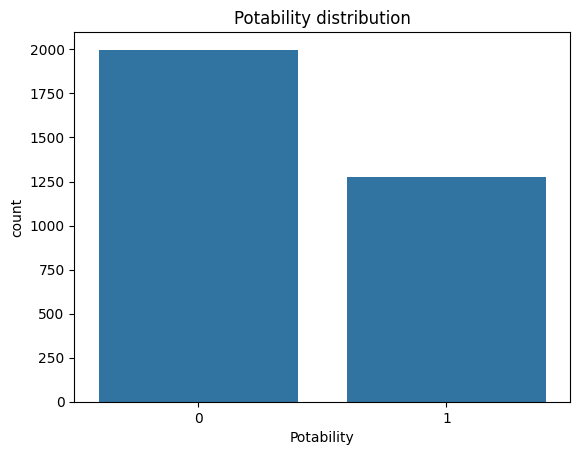

In [24]:
water = pd.read_csv(WATER_CSV)

print("Shape:", water.shape)
display(water.head(10))

print("\nMissing values:")
print(water.isnull().sum())

print("\nPotability distribution:")
print(water['Potability'].value_counts())
print(water['Potability'].value_counts(normalize=True).round(3))

sns.countplot(data=water, x='Potability')
plt.title('Potability distribution')
plt.show()

## Stratified 80-20 split

In [25]:
X = water.drop('Potability', axis=1)
y = water['Potability']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)
print("Train class ratio:", y_train.mean().round(3), "| Test class ratio:", y_test.mean().round(3))

(2620, 9) (656, 9)
Train class ratio: 0.39 | Test class ratio: 0.39


## Missing values

In [26]:
train_medians = X_train.median()
print(train_medians[['ph', 'Sulfate', 'Trihalomethanes']])

X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

print("Missing after filling (train/test):", X_train.isnull().sum().sum(), X_test.isnull().sum().sum())

ph                   7.035037
Sulfate            333.073546
Trihalomethanes     66.565709
dtype: float64
Missing after filling (train/test): 0 0


## Single models and the voting ensembles

In [27]:
lr  = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
svc = make_pipeline(StandardScaler(), SVC(probability=True, random_state=42))
rf  = RandomForestClassifier(n_estimators=100, random_state=42)

estimators = [('lr', lr), ('svc', svc), ('rf', rf)]

voting_hard = VotingClassifier(estimators, voting='hard')
voting_soft = VotingClassifier(estimators, voting='soft')

for m in (lr, svc, rf, voting_hard, voting_soft):
    m.fit(X_train, y_train)

## Bagging, pasting and a single decision tree

In [28]:
def make_bag(n, bootstrap):
    return BaggingClassifier(
        DecisionTreeClassifier(random_state=42),
        n_estimators=n, max_samples=0.5, bootstrap=bootstrap, random_state=42
    )

bag_10    = make_bag(10, True)
bag_100   = make_bag(100, True)
paste_100 = make_bag(100, False)      # pasting: sampling without replacement
single_tree = DecisionTreeClassifier(random_state=42)

for m in (bag_10, bag_100, paste_100, single_tree):
    m.fit(X_train, y_train)

## Comparing all models on the test set

In [29]:
models = {
    'Logistic Regression': lr,
    'SVC': svc,
    'Random Forest': rf,
    'Decision Tree (single)': single_tree,
    'Voting (hard)': voting_hard,
    'Voting (soft)': voting_soft,
    'Bagging (10 trees)': bag_10,
    'Bagging (100 trees)': bag_100,
    'Pasting (100 trees)': paste_100,
}

rows = []
for name, m in models.items():
    pred = m.predict(X_test)
    rows.append({
        'Model': name,
        'Accuracy':  accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall':    recall_score(y_test, pred),
        'F1-score':  f1_score(y_test, pred),
    })

results = pd.DataFrame(rows).set_index('Model').round(4)
display(results.sort_values('Accuracy', ascending=False))

,Accuracy,Precision,Recall,F1-score
Model,,,,
Voting (hard),0.6738,0.7838,0.2266,0.3515
Pasting (100 trees),0.6723,0.6454,0.3555,0.4584
Voting (soft),0.6707,0.7222,0.2539,0.3757
SVC,0.6707,0.7041,0.2695,0.3898
Random Forest,0.6631,0.6446,0.3047,0.4138
Bagging (100 trees),0.6494,0.6048,0.2930,0.3947
Bagging (10 trees),0.6387,0.5736,0.2891,0.3844
Logistic Regression,0.6098,0.0000,0.0000,0.0000
Decision Tree (single),0.5960,0.4813,0.4531,0.4668


Best model by accuracy: Voting (hard)


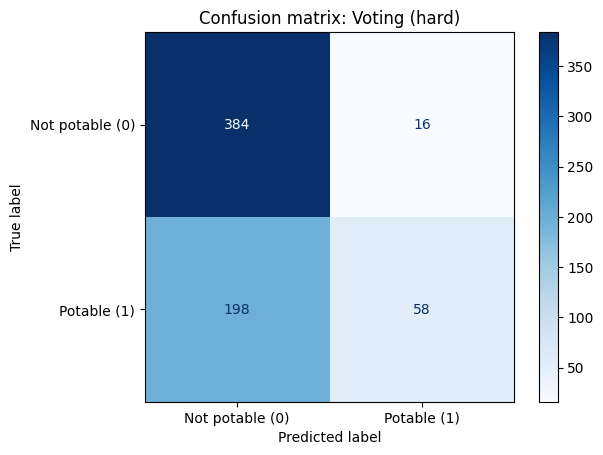

In [30]:
best_name = results['Accuracy'].idxmax()
print("Best model by accuracy:", best_name)

ConfusionMatrixDisplay.from_estimator(models[best_name], X_test, y_test,
                                      display_labels=['Not potable (0)', 'Potable (1)'], cmap='Blues')
plt.title(f'Confusion matrix: {best_name}')
plt.show()

In [31]:
singles = ['Logistic Regression', 'SVC', 'Random Forest', 'Decision Tree (single)']
ensembles = [n for n in results.index if n not in singles]

best_single = results.loc[singles, 'Accuracy'].idxmax()
best_ens = results.loc[ensembles, 'Accuracy'].idxmax()
s_acc, e_acc = results.loc[best_single, 'Accuracy'], results.loc[best_ens, 'Accuracy']

print(f"Best single model : {best_single} ({s_acc:.4f})")
print(f"Best ensemble     : {best_ens} ({e_acc:.4f})")
print("Voting/bagging beat the best single model." if e_acc > s_acc
      else "No voting/bagging ensemble beat the best single model.")

Best single model : SVC (0.6707)
Best ensemble     : Voting (hard) (0.6738)
Voting/bagging beat the best single model.


# Activity 2 - 1186

## Load the data

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No



Missing values (NaN):
none

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


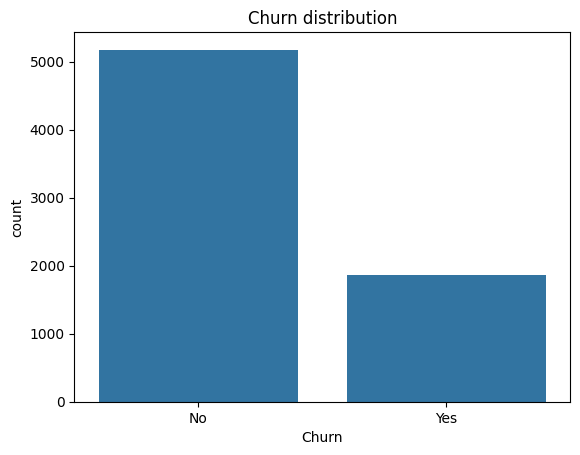

In [32]:
telco = pd.read_csv(TELCO_CSV)

print("Shape:", telco.shape)
display(telco.head(10))

print("\nMissing values (NaN):")
print(telco.isnull().sum()[lambda s: s > 0] if telco.isnull().sum().sum() else "none")

print("\nChurn distribution:")
print(telco['Churn'].value_counts())
print(telco['Churn'].value_counts(normalize=True).round(3))

sns.countplot(data=telco, x='Churn')
plt.title('Churn distribution')
plt.show()

## TotalCharges

In [33]:
telco['TotalCharges'] = pd.to_numeric(telco['TotalCharges'], errors='coerce')

blank = telco[telco['TotalCharges'].isnull()]
print("Rows with blank TotalCharges:", len(blank))
display(blank[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])
print("All of them have tenure == 0:", (blank['tenure'] == 0).all())

Rows with blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


All of them have tenure == 0: True


In [34]:
telco['TotalCharges'] = telco['TotalCharges'].fillna(0)
print("Remaining NaN in TotalCharges:", telco['TotalCharges'].isnull().sum())

Remaining NaN in TotalCharges: 0


## Drop ID, encode the target, one-hot encode, split

In [35]:
telco = telco.drop('customerID', axis=1)
telco['Churn'] = telco['Churn'].map({'Yes': 1, 'No': 0})

cat_cols = telco.select_dtypes(include='object').columns.tolist()
print("Categorical columns:", cat_cols)

telco_enc = pd.get_dummies(telco, columns=cat_cols, drop_first=True, dtype=int)

X = telco_enc.drop('Churn', axis=1)
y = telco_enc['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)
print("Churn rate train/test:", y_train.mean().round(3), y_test.mean().round(3))

Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
(5634, 30) (1409, 30)
Churn rate train/test: 0.265 0.265


C:\Users\hamza\AppData\Local\Temp\ipykernel_22724\2227453114.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = telco.select_dtypes(include='object').columns.tolist()


## Default boosting models

In [36]:
gb  = GradientBoostingClassifier(random_state=42)
ada = AdaBoostClassifier(random_state=42)
xgb_default = XGBClassifier(random_state=42)

for m in (gb, ada, xgb_default):
    m.fit(X_train, y_train)

def evaluate(model, X, y):
    pred = model.predict(X)
    proba = model.predict_proba(X)[:, 1]
    return {
        'Accuracy':  accuracy_score(y, pred),
        'Precision': precision_score(y, pred, zero_division=0),
        'Recall':    recall_score(y, pred),
        'F1-score':  f1_score(y, pred),
        'ROC-AUC':   roc_auc_score(y, proba),
    }

default_results = pd.DataFrame({
    'GradientBoosting': evaluate(gb, X_test, y_test),
    'AdaBoost': evaluate(ada, X_test, y_test),
    'XGBoost (default)': evaluate(xgb_default, X_test, y_test),
}).T.round(4)
display(default_results)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
GradientBoosting,0.7984,0.6552,0.5080,0.5723,0.8422
AdaBoost,0.8048,0.6623,0.5401,0.5950,0.8407
XGBoost (default),0.7764,0.5891,0.5214,0.5532,0.8183


## Tune XGBClassifier with GridSearchCV


In [37]:
param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5],
    'subsample': [0.8, 1.0],
}

grid = GridSearchCV(
    XGBClassifier(random_state=42),
    param_grid, cv=5, scoring='f1', n_jobs=-1, verbose=1
)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV F1-score:", round(grid.best_score_, 4))

xgb_tuned = grid.best_estimator_

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}
Best CV F1-score: 0.5873


## Default vs tuned XGBoost on the test set

In [38]:
comparison = pd.DataFrame({
    'XGBoost (default)': evaluate(xgb_default, X_test, y_test),
    'XGBoost (tuned)':   evaluate(xgb_tuned, X_test, y_test),
}).T.round(4)
display(comparison)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
XGBoost (default),0.7764,0.5891,0.5214,0.5532,0.8183
XGBoost (tuned),0.8027,0.6633,0.5214,0.5838,0.8454


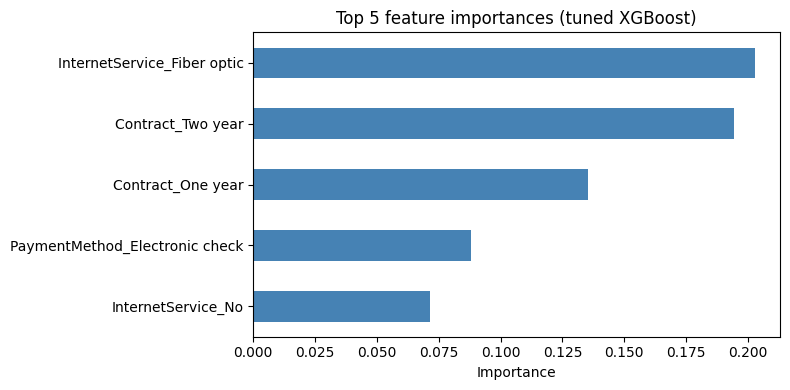

In [39]:
imp = pd.Series(xgb_tuned.feature_importances_, index=X_train.columns).nlargest(5).sort_values()

plt.figure(figsize=(8, 4))
imp.plot(kind='barh', color='steelblue')
plt.title('Top 5 feature importances (tuned XGBoost)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

In [40]:
majority_acc = 1 - y_test.mean()
print(f"Always predicting 'No churn' gives accuracy = {majority_acc:.4f}")
print(f"Tuned XGBoost accuracy                      = {accuracy_score(y_test, xgb_tuned.predict(X_test)):.4f}")
print(f"Tuned XGBoost recall on churners            = {recall_score(y_test, xgb_tuned.predict(X_test)):.4f}")

Always predicting 'No churn' gives accuracy = 0.7346
Tuned XGBoost accuracy                      = 0.8027
Tuned XGBoost recall on churners            = 0.5214


# Activity 3 - 1186

## load dataset

In [41]:

from sklearn.linear_model import Ridge, LinearRegression


In [42]:
df = pd.read_csv("insurance.csv")

print("Shape:", df.shape)

print("\nFirst 10 Rows:")
print(df.head(10))

print("\nMissing Values:")
print(df.isnull().sum())

print("\nCharges Summary:")
print(df["charges"].describe())

Shape: (1338, 7)

First 10 Rows:
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
5   31  female  25.740         0     no  southeast   3756.62160
6   46  female  33.440         1     no  southeast   8240.58960
7   37  female  27.740         3     no  northwest   7281.50560
8   37    male  29.830         2     no  northeast   6406.41070
9   60  female  25.840         0     no  northwest  28923.13692

Missing Values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Charges Summary:
count     1338.000000
mean     13270.422265
std      12110.011237
min       1121.873900
25%       4740.287150
50%    

## Encode categorical columns and split data

In [43]:

df["sex"] = df["sex"].map({"female": 0, "male": 1})
df["smoker"] = df["smoker"].map({"no": 0, "yes": 1})

df = pd.get_dummies(df, columns=["region"], dtype=int)

X = df.drop("charges", axis=1)
y = df["charges"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (1070, 9)
Testing Shape: (268, 9)


## Train three regression models separately

In [48]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

gb = GradientBoostingRegressor(
    random_state=42
)

ridge.fit(X_train, y_train)
rf.fit(X_train, y_train)
gb.fit(X_train, y_train)



,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are""friedman_mse"" for the mean squared error with improvement score byFriedman, ""squared_error"" for mean squared error. The default value of""friedman_mse"" is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft 

## Build Stacking Regressor

In [47]:
from sklearn.ensemble import StackingRegressor

stack = StackingRegressor(
    estimators=[
        ("ridge", ridge),
        ("random_forest", rf),
        ("gradient_boosting", gb)
    ],
    final_estimator=LinearRegression(),
    cv=5
)

stack.fit(X_train, y_train)


,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.","[('ridge', ...), ('random_forest', ...), ...]"
,"final_estimator final_estimator: estimator, default=NoneA regressor which will be used to combine the base estimators.The default regressor is a :class:`~sklearn.linear_model.RidgeCV`.",LinearRegression()
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary ` for more details.",None
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.

## Compare all four models

In [49]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Ridge": ridge,
    "Random Forest": rf,
    "Gradient Boosting": gb,
    "Stacking": stack
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results)

print(results_df.round(3).to_string(index=False))

            Model      MAE     RMSE    R2
            Ridge 4182.753 5796.944 0.784
    Random Forest 2555.386 4597.769 0.864
Gradient Boosting 2407.288 4332.103 0.879
         Stacking 2371.724 4315.685 0.880


## Print coefficients and plot actual vs predicted charges

Final Estimator Coefficients:
Ridge: 0.0965
Random Forest: 0.2256
Gradient Boosting: 0.6852
Intercept: -179.8816


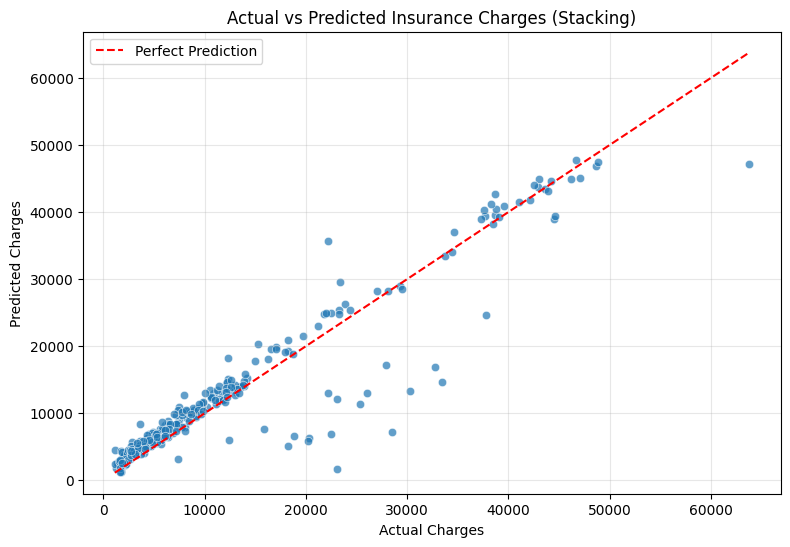


Most Trusted Base Model: Gradient Boosting


In [50]:
coefficients = stack.final_estimator_.coef_
intercept = stack.final_estimator_.intercept_

base_models = ["Ridge", "Random Forest", "Gradient Boosting"]

print("Final Estimator Coefficients:")

for name, coef in zip(base_models, coefficients):
    print(f"{name}: {coef:.4f}")

print("Intercept:", round(intercept, 4))

y_pred_stack = stack.predict(X_test)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred_stack,
    alpha=0.7
)

min_value = min(y_test.min(), y_pred_stack.min())
max_value = max(y_test.max(), y_pred_stack.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Actual vs Predicted Insurance Charges (Stacking)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("\nMost Trusted Base Model:",
      base_models[np.argmax(coefficients)])